
# GLOBAL SOLUTION 2026 — CITIZENTECH

## ANÁLISE ESTATÍSTICA DA POLUIÇÃO DO AR

**Disciplina:** Modelagem Linear para Aprendizado de Máquina (MLAM)

**Tema:** Poluição atmosférica e concentração de partículas PM2.5

**Base de dados:** Beijing PM2.5 — UCI Machine Learning Repository

**Integrantes:**
- Arthur Araujo Massarioli — RM: 573308
- Daniel Alejandro Pupo Martinez — RM: 573075
- Wendel Pedro Rezende — RM: 573126

**Ferramenta:** Python — Google Colab

**Ano:** 2026

---

### Objetivo do projeto

Investigar a concentração de partículas finas
(PM2.5) na atmosfera e analisar sua relação
com variáveis meteorológicas, utilizando
métodos estatísticos e modelos de regressão.

O estudo busca identificar padrões, relações
e possibilidades de previsão da concentração
de poluentes atmosféricos.



# 1. Introdução

A poluição atmosférica representa um importante
desafio ambiental e de saúde pública.

Neste projeto, será analisada a concentração de
partículas finas PM2.5, utilizando uma base de
dados real da cidade de Pequim, na China.

A investigação utilizará técnicas de estatística
descritiva, probabilidade, testes de hipóteses,
análise bivariada e multivariada, regressão linear
e regressão logística.

O objetivo é identificar padrões nos dados e
investigar possíveis relações entre as condições
meteorológicas e a concentração de partículas
na atmosfera.



# 2. Identificação da base de dados

A base utilizada neste estudo é a Beijing PM2.5,
disponibilizada pelo UCI Machine Learning Repository.

Os dados apresentam medições horárias realizadas
em Pequim, entre 2010 e 2014.

A base contém informações sobre:
- Concentração de partículas PM2.5;
- Temperatura;
- Pressão atmosférica;
- Ponto de orvalho;
- Velocidade e direção do vento;
- Registros de chuva e neve.

**Fonte oficial:**
https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data


## Instalação da Base de Dados

In [1]:
# Instalação da biblioteca
!pip -q install ucimlrepo

# 3. Importação e exploração dos dados

In [2]:
# Importação das bibliotecas
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

# Busca da base de dados na UCI
beijing = fetch_ucirepo(id=381)

# Separação das variáveis explicativas e da variável alvo
X = beijing.data.features
y = beijing.data.targets

# União dos dados
df = pd.concat([X, y], axis=1)

# Visualização inicial
df.head()

,year,month,day,hour,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,pm2.5
0,2010,1,1,0,-21,-11.0,1021.0,NW,1.79,0,0,NaN
1,2010,1,1,1,-21,-12.0,1020.0,NW,4.92,0,0,NaN
2,2010,1,1,2,-21,-11.0,1019.0,NW,6.71,0,0,NaN
3,2010,1,1,3,-21,-14.0,1019.0,NW,9.84,0,0,NaN
4,2010,1,1,4,-20,-12.0,1018.0,NW,12.97,0,0,NaN


In [3]:
# Quantidade de linhas e colunas
print("Dimensões da base:")
print(df.shape)

# Informações das variáveis
print()
print("Informações da base:")
df.info()

# Verificação de valores ausentes
print()
print("Valores ausentes:")
print(df.isnull().sum())

# Estatísticas descritivas
print()
print("Estatísticas:")
display(df.describe())

Dimensões da base:
(43824, 12)

Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    43824 non-null  int64  
 1   month   43824 non-null  int64  
 2   day     43824 non-null  int64  
 3   hour    43824 non-null  int64  
 4   DEWP    43824 non-null  int64  
 5   TEMP    43824 non-null  float64
 6   PRES    43824 non-null  float64
 7   cbwd    43824 non-null  object 
 8   Iws     43824 non-null  float64
 9   Is      43824 non-null  int64  
 10  Ir      43824 non-null  int64  
 11  pm2.5   41757 non-null  float64
dtypes: float64(4), int64(7), object(1)
memory usage: 4.0+ MB

Valores ausentes:
year        0
month       0
day         0
hour        0
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
pm2.5    2067
dtype: int64

Estatísticas:


,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir,pm2.5
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,41757.000000
mean,2012.000000,6.523549,15.727820,11.500000,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916,98.613215
std,1.413842,3.448572,8.799425,6.922266,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867,92.050387
min,2010.000000,1.000000,1.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000,0.000000
25%,2011.000000,4.000000,8.000000,5.750000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000,29.000000
50%,2012.000000,7.000000,16.000000,11.500000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000,72.000000
75%,2013.000000,10.000000,23.000000,17.250000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000,137.000000
max,2014.000000,12.000000,31.000000,23.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000,994.000000


# 4. Limpeza e preparação dos dados

In [4]:
# Criando uma cópia da base original
df_limpo = df.copy()

# Removendo somente registros sem concentração de PM2.5
df_limpo = df_limpo.dropna(subset=['pm2.5']).copy()

# Conferindo o resultado
print("Dimensões da base original:", df.shape)
print("Dimensões da base limpa:", df_limpo.shape)

print()
print("Valores ausentes após a limpeza:")
print(df_limpo.isnull().sum())

print()
print("Total de registros removidos:")
print(len(df) - len(df_limpo))

Dimensões da base original: (43824, 12)
Dimensões da base limpa: (41757, 12)

Valores ausentes após a limpeza:
year     0
month    0
day      0
hour     0
DEWP     0
TEMP     0
PRES     0
cbwd     0
Iws      0
Is       0
Ir       0
pm2.5    0
dtype: int64

Total de registros removidos:
2067


# 4. Salvando a base em .csv

In [5]:
# Salvando a base original e a base limpa em .csv
df.to_csv('beijing_pm25_original.csv', index=False)
df_limpo.to_csv('beijing_pm25_limpo.csv', index=False)

print("Arquivos salvos: beijing_pm25_original.csv e beijing_pm25_limpo.csv")

Arquivos salvos: beijing_pm25_original.csv e beijing_pm25_limpo.csv


# 5. Análise exploratória

count    41757.000000
mean        98.613215
std         92.050387
min          0.000000
25%         29.000000
50%         72.000000
75%        137.000000
max        994.000000
Name: pm2.5, dtype: float64


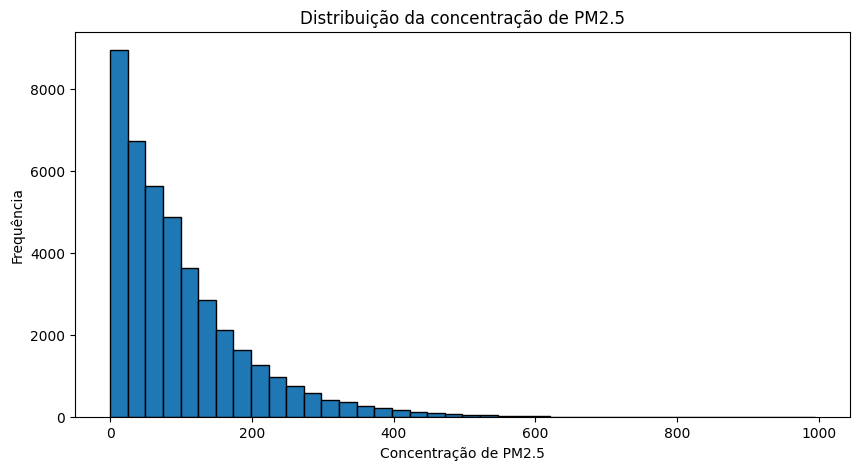

In [6]:
import matplotlib.pyplot as plt

# Estatísticas da concentração de PM2.5
print(df_limpo['pm2.5'].describe())

# Histograma da concentração de PM2.5
plt.figure(figsize=(10, 5))

plt.hist(df_limpo['pm2.5'], bins=40, edgecolor='black')

plt.title('Distribuição da concentração de PM2.5')
plt.xlabel('Concentração de PM2.5')
plt.ylabel('Frequência')

plt.show()

## 6. Distribuição normal de probabilidade

Nesta etapa, será analisada a variável PM2.5,
considerando uma distribuição normal definida
pela média e pelo desvio padrão dos registros válidos.

Serão calculadas as probabilidades de a concentração
ser inferior à média e superior à mediana.



In [7]:
from scipy.stats import norm

# Parâmetros da distribuição
media = df_limpo['pm2.5'].mean()
desvio_padrao = df_limpo['pm2.5'].std()
mediana = df_limpo['pm2.5'].median()

# Questão A: probabilidade inferior à média
prob_a = norm.cdf(media, loc=media, scale=desvio_padrao)

# Questão B: probabilidade superior à mediana
prob_b = norm.sf(mediana, loc=media, scale=desvio_padrao)

print("DISTRIBUIÇÃO NORMAL - PM2.5")
print(f"Média: {media:.4f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio padrão: {desvio_padrao:.4f}")

print()
print(f"Questão A: {prob_a:.4f} ({prob_a*100:.2f}%)")
print(f"Questão B: {prob_b:.4f} ({prob_b*100:.2f}%)")


DISTRIBUIÇÃO NORMAL - PM2.5
Média: 98.6132
Mediana: 72.00
Desvio padrão: 92.0504

Questão A: 0.5000 (50.00%)
Questão B: 0.6138 (61.38%)


## 6.1. Interpretação dos resultados

**Questão A:** A probabilidade de a concentração
de PM2.5 ser inferior à média é de 50%.
O evento é classificado como igualmente provável.

**Questão B:** A probabilidade de a concentração
ser superior à mediana é de aproximadamente 61,38%.
O evento é classificado como provável.


## 7. Testes de Hipóteses para a média

Serão realizados dois testes Z unilaterais para
investigar se a média da concentração de PM2.5
é inferior ou superior à média de referência.

Serão utilizadas amostras aleatórias de 20 e 25
registros, com níveis de significância de 6% e 9%.



In [8]:
# Parâmetros de referência
media_pop = df_limpo['pm2.5'].mean()
desvio_pop = df_limpo['pm2.5'].std(ddof=0)

print(f"Média de referência: {media_pop:.4f}")
print(f"Desvio padrão populacional: {desvio_pop:.4f}")


Média de referência: 98.6132
Desvio padrão populacional: 92.0493


In [9]:
from scipy.stats import norm
import numpy as np
import pandas as pd

# TESTE A: média inferior
n_a = 20
alpha_a = 0.06

amostra_a = df_limpo['pm2.5'].sample(
    n=n_a, random_state=42
)

media_a = amostra_a.mean()

z_a = (media_a - media_pop) / (
    desvio_pop / np.sqrt(n_a)
)

p_a = norm.cdf(z_a)
critico_a = norm.ppf(alpha_a)

decisao_a = (
    "Rejeitar H0" if p_a < alpha_a
    else "Não rejeitar H0"
)

# TESTE B: média superior
n_b = 25
alpha_b = 0.09

amostra_b = df_limpo['pm2.5'].sample(
    n=n_b, random_state=43
)

media_b = amostra_b.mean()

z_b = (media_b - media_pop) / (
    desvio_pop / np.sqrt(n_b)
)

p_b = norm.sf(z_b)
critico_b = norm.ppf(1 - alpha_b)

decisao_b = (
    "Rejeitar H0" if p_b < alpha_b
    else "Não rejeitar H0"
)

# Tabela comparativa
resultados = pd.DataFrame({
    'Teste': ['A - Média inferior', 'B - Média superior'],
    'Amostra': [n_a, n_b],
    'Média amostral': [media_a, media_b],
    'Significância': [alpha_a, alpha_b],
    'Z calculado': [z_a, z_b],
    'Z crítico': [critico_a, critico_b],
    'P-valor': [p_a, p_b],
    'Decisão': [decisao_a, decisao_b]
})

display(resultados.round(4))


,Teste,Amostra,Média amostral,Significância,Z calculado,Z crítico,P-valor,Decisão
0,A - Média inferior,20,95.95,0.06,-0.1294,-1.5548,0.4485,Não rejeitar H0
1,B - Média superior,25,91.76,0.09,-0.3723,1.3408,0.6451,Não rejeitar H0


## 7.1. Formulação das hipóteses

**Teste A — Média inferior**

H0: μ = μ0

H1: μ < μ0

Nível de significância: 6%.

**Teste B — Média superior**

H0: μ = μ0

H1: μ > μ0

Nível de significância: 9%.

## 7.2. Interpretação dos resultados

**Teste A — Média inferior**

O p-valor obtido foi de 0,4485, superior ao nível de significância de 6%. Portanto, não rejeitamos a hipótese nula. Não foram encontradas evidências estatísticas suficientes para afirmar que a média da concentração de PM2.5 é inferior à média de referência.

**Teste B — Média superior**

O p-valor obtido foi de 0,6451, superior ao nível de significância de 9%. Portanto, também não rejeitamos a hipótese nula. Não foram encontradas evidências estatísticas suficientes para afirmar que a média da concentração de PM2.5 é superior à média de referência.

**Observação metodológica:** os testes utilizam a própria base de dados para estabelecer a média e o desvio padrão de referência e também para selecionar as amostras. Portanto, os resultados devem ser interpretados como uma aplicação didática dos testes Z, e não como uma inferência independente sobre parâmetros populacionais conhecidos.

## 8. Análise Bivariada

A análise bivariada permite investigar a relação entre duas variáveis quantitativas. Nesta etapa, será analisada a relação entre a concentração de PM2.5 e o ponto de orvalho (DEWP).

### 8.1. Variáveis utilizadas

Foi escolhida uma variável meteorológica (ponto de orvalho) para tentar explicar a concentração de PM2.5.

- Variável dependente (y): PM2.5
- Variável independente (x): ponto de orvalho (DEWP)

**a) Gráfico de dispersão**

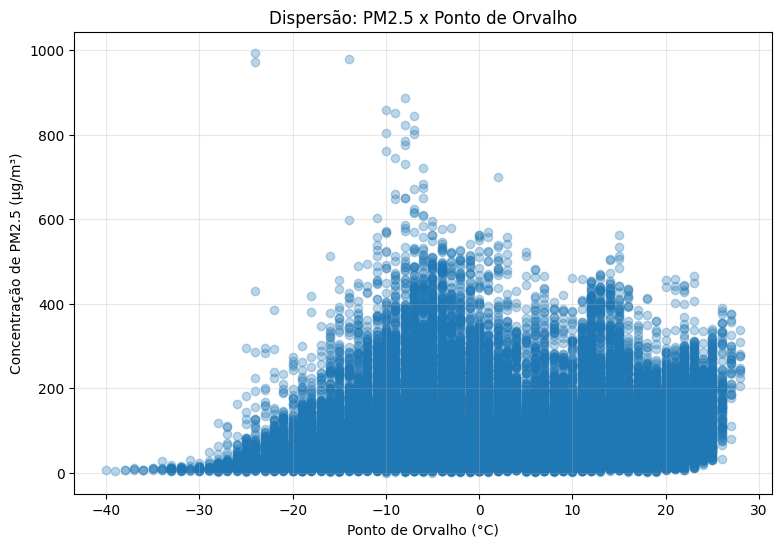

In [10]:
plt.figure(figsize=(9, 6))
plt.scatter(df_limpo['DEWP'], df_limpo['pm2.5'], alpha=0.3)
plt.title('Dispersão: PM2.5 x Ponto de Orvalho')
plt.xlabel('Ponto de Orvalho (°C)')
plt.ylabel('Concentração de PM2.5 (µg/m³)')
plt.grid(alpha=0.3)
plt.show()

**Interpretação (a):** os pontos formam uma nuvem bastante espalhada, com leve tendência de PM2.5 maior quando o ponto de orvalho é maior. Não há uma relação linear clara: para um mesmo valor de ponto de orvalho existem concentrações muito baixas e muito altas.

**b) Covariância e correlação linear de Pearson**

In [11]:
import numpy as np

covariancia = np.cov(df_limpo['DEWP'], df_limpo['pm2.5'])[0, 1]
correlacao = np.corrcoef(df_limpo['DEWP'], df_limpo['pm2.5'])[0, 1]

print(f"Covariância (DEWP, PM2.5): {covariancia:.4f}")
print(f"Correlação de Pearson (DEWP, PM2.5): {correlacao:.4f}")

Covariância (DEWP, PM2.5): 227.7570
Correlação de Pearson (DEWP, PM2.5): 0.1714


**Interpretação (b):** a covariância é positiva (227,76), o que indica que as duas variáveis tendem a variar no mesmo sentido. Como a covariância depende da unidade de medida, a interpretação da intensidade é feita pela correlação: r = 0,1714, uma correlação positiva **fraca**.

**c) Gráfico de correlação linear de Pearson**

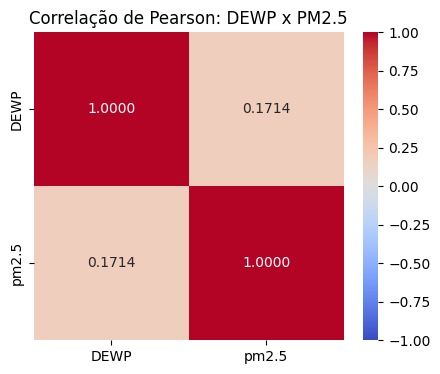

In [12]:
import seaborn as sns

matriz_corr_biv = df_limpo[['DEWP', 'pm2.5']].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(matriz_corr_biv, annot=True, fmt='.4f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlação de Pearson: DEWP x PM2.5')
plt.show()

**Interpretação (c):** o mapa de calor mostra correlação de 0,17 entre as variáveis, valor próximo de zero na escala de -1 a 1 (cores claras). Confirma uma associação linear positiva, porém fraca.

**d) Reta de regressão linear simples e equação**

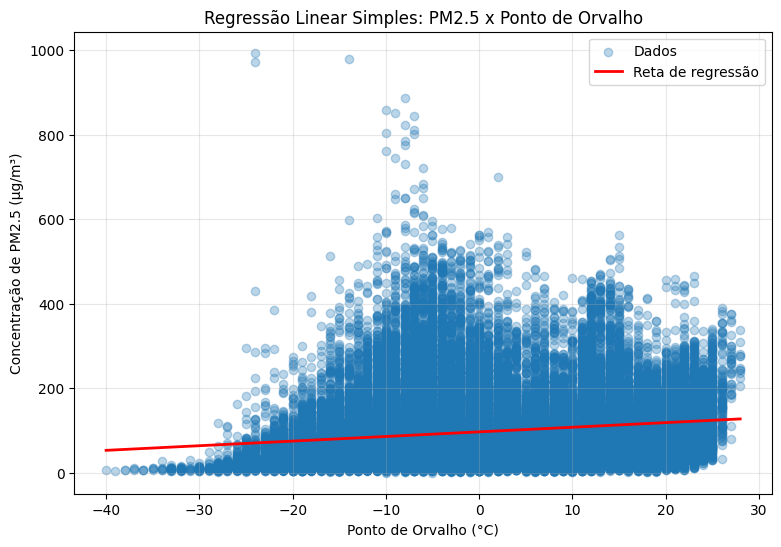

Equação: PM2.5 = 96.6998 + 1.0932 * DEWP


In [13]:
import statsmodels.api as sm

x_simples = sm.add_constant(df_limpo['DEWP'])
modelo_simples = sm.OLS(df_limpo['pm2.5'], x_simples).fit()

b0 = modelo_simples.params['const']
b1 = modelo_simples.params['DEWP']

plt.figure(figsize=(9, 6))
plt.scatter(df_limpo['DEWP'], df_limpo['pm2.5'], alpha=0.3, label='Dados')
x_linha = np.linspace(df_limpo['DEWP'].min(), df_limpo['DEWP'].max(), 100)
plt.plot(x_linha, b0 + b1 * x_linha, color='red', linewidth=2, label='Reta de regressão')
plt.title('Regressão Linear Simples: PM2.5 x Ponto de Orvalho')
plt.xlabel('Ponto de Orvalho (°C)')
plt.ylabel('Concentração de PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Equação: PM2.5 = {b0:.4f} + {b1:.4f} * DEWP")

**Equação da reta:** PM2.5 = 96,6998 + 1,0932 × DEWP

**Interpretação (d):** o coeficiente angular indica que, em média, cada aumento de 1 °C no ponto de orvalho está associado a um aumento de cerca de 1,09 µg/m³ na concentração de PM2.5. O intercepto (96,70) é o valor estimado quando DEWP = 0 °C. A reta é pouco inclinada em relação à dispersão dos dados.

**e) Adequação do modelo (R² e teste F)**

Teste F: H0: o modelo não é útil (β1 = 0) | H1: o modelo é útil (β1 ≠ 0). Nível de significância: 5%.

In [14]:
r2_simples = modelo_simples.rsquared
f_simples = modelo_simples.fvalue
p_f_simples = modelo_simples.f_pvalue

print(f"R²: {r2_simples:.4f}")
print(f"Estatística F: {f_simples:.2f}")
print(f"P-valor do teste F: {p_f_simples:.2e}")

if p_f_simples < 0.05:
    print("Decisão: rejeitar H0 (o modelo é estatisticamente significativo).")
else:
    print("Decisão: não rejeitar H0.")

R²: 0.0294
Estatística F: 1264.16
P-valor do teste F: 8.36e-273
Decisão: rejeitar H0 (o modelo é estatisticamente significativo).


**Interpretação (e):** o p-valor do teste F é praticamente zero (menor que 5%), então rejeitamos H0: existe relação linear estatisticamente significativa entre DEWP e PM2.5. Porém, o R² é de apenas 0,0294, ou seja, o ponto de orvalho explica somente cerca de 2,9% da variação do PM2.5. A base tem muitas observações (mais de 41 mil), o que torna significativo até um efeito pequeno. Portanto, o modelo é significativo, mas **fraco para fazer previsões**.

**f) Previsão**

In [15]:
dewp_novo = 10  # ponto de orvalho de 10 °C
previsao_simples = b0 + b1 * dewp_novo

print(f"Previsão de PM2.5 para DEWP = {dewp_novo} °C: {previsao_simples:.2f} µg/m³")

Previsão de PM2.5 para DEWP = 10 °C: 107.63 µg/m³


**Interpretação (f):** para um ponto de orvalho de 10 °C, o modelo prevê PM2.5 de aproximadamente 107,63 µg/m³. Como o R² é baixo, essa previsão deve ser vista apenas como uma estimativa média, com grande incerteza.

## 9. Regressão Linear Múltipla

A regressão linear múltipla é uma técnica estatística que permite analisar a relação entre uma variável dependente e várias variáveis independentes.

Neste projeto, a variável dependente será a concentração de PM2.5, enquanto as variáveis independentes serão variáveis meteorológicas (temperatura, ponto de orvalho, pressão atmosférica e velocidade do vento).

O objetivo é avaliar quanto essas variáveis conseguem explicar e estimar a concentração de partículas PM2.5.

### 9.1. Variáveis utilizadas

Para a análise multivariada completa serão usadas cinco variáveis quantitativas (a dependente e quatro explicativas):

- PM2.5 (variável dependente);
- TEMP: temperatura (°C);
- DEWP: ponto de orvalho (°C);
- PRES: pressão atmosférica (hPa);
- Iws: velocidade acumulada do vento (m/s).

**a) Gráfico de dispersão (matriz de dispersão)**

Para o gráfico ficar legível e rápido de gerar, é usada uma amostra aleatória de 3.000 registros.

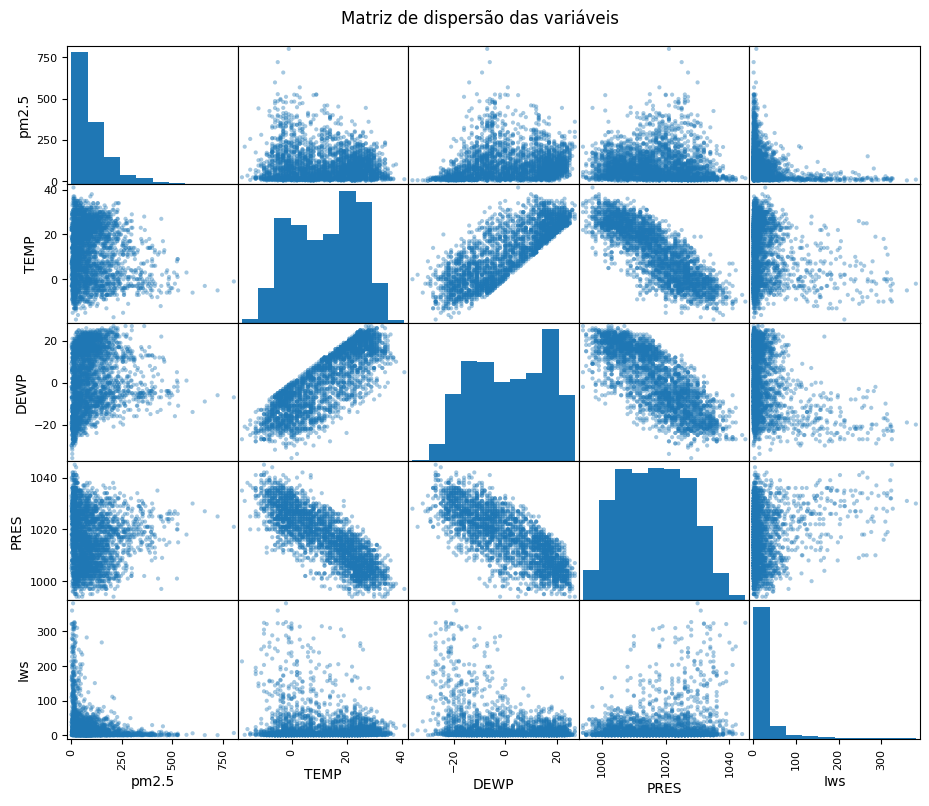

In [16]:
from pandas.plotting import scatter_matrix

variaveis_multi = ['pm2.5', 'TEMP', 'DEWP', 'PRES', 'Iws']
amostra_grafico = df_limpo[variaveis_multi].sample(n=3000, random_state=42)

scatter_matrix(amostra_grafico, figsize=(11, 9), alpha=0.4, diagonal='hist')
plt.suptitle('Matriz de dispersão das variáveis', y=0.92)
plt.show()

**Interpretação (a):** na linha/coluna do PM2.5 os pontos estão muito espalhados, sem padrão linear forte. Já entre as variáveis meteorológicas há relações mais nítidas: TEMP e DEWP crescem juntas, enquanto TEMP e PRES seguem sentidos opostos. Isso indica que as variáveis explicativas são parecidas entre si (multicolinearidade).

**b) Matriz de covariância e matriz de correlação de Pearson**

In [17]:
matriz_cov = df_limpo[variaveis_multi].cov()
matriz_corr = df_limpo[variaveis_multi].corr()

print("MATRIZ DE COVARIÂNCIA")
display(matriz_cov.round(2))

print("MATRIZ DE CORRELAÇÃO DE PEARSON")
display(matriz_corr.round(3))

MATRIZ DE COVARIÂNCIA


,pm2.5,TEMP,DEWP,PRES,Iws
pm2.5,8473.27,-101.46,227.76,-44.83,-1131.71
TEMP,-101.46,148.24,144.77,-103.70,-90.38
DEWP,227.76,144.77,208.33,-115.63,-209.91
PRES,-44.83,-103.70,-115.63,106.11,91.42
Iws,-1131.71,-90.38,-209.91,91.42,2461.90


MATRIZ DE CORRELAÇÃO DE PEARSON


,pm2.5,TEMP,DEWP,PRES,Iws
pm2.5,1.000,-0.091,0.171,-0.047,-0.248
TEMP,-0.091,1.000,0.824,-0.827,-0.150
DEWP,0.171,0.824,1.000,-0.778,-0.293
PRES,-0.047,-0.827,-0.778,1.000,0.179
Iws,-0.248,-0.150,-0.293,0.179,1.000


**Interpretação (b):**

- Com o PM2.5, as correlações são todas fracas: Iws (-0,248), DEWP (0,171), TEMP (-0,091) e PRES (-0,047). A velocidade do vento tem a maior associação, e o sinal negativo faz sentido: vento mais forte dispersa as partículas.
- Entre as variáveis explicativas, as correlações são fortes: TEMP e DEWP (0,824), TEMP e PRES (-0,827), DEWP e PRES (-0,778). Isso pode dificultar a interpretação individual dos coeficientes da regressão.
- A covariância tem o mesmo sinal da correlação, mas depende da unidade de cada variável, por isso a intensidade é avaliada pela correlação.

**c) Gráfico de correlação linear de Pearson**

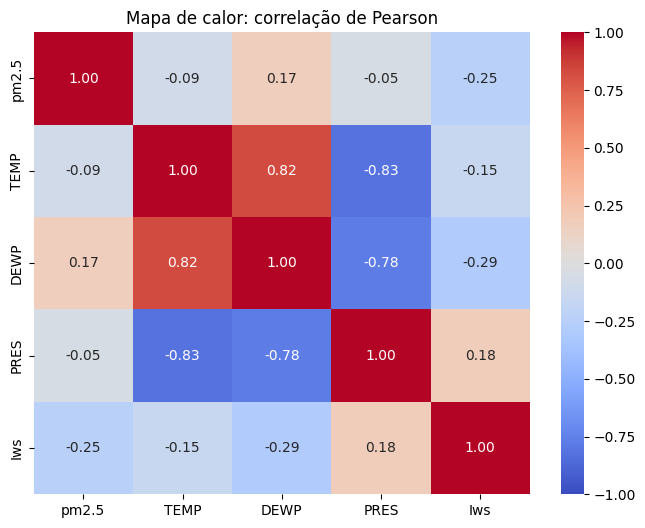

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de calor: correlação de Pearson')
plt.show()

**Interpretação (c):** o mapa de calor mostra blocos de cores fortes entre TEMP, DEWP e PRES (correlações acima de 0,77 em módulo) e cores claras na linha do PM2.5, confirmando que nenhuma variável isolada explica bem o PM2.5.

**d) Equação da regressão linear múltipla**

Modelo: PM2.5 = β0 + β1·TEMP + β2·DEWP + β3·PRES + β4·Iws

In [19]:
X_multi = sm.add_constant(df_limpo[['TEMP', 'DEWP', 'PRES', 'Iws']])
modelo_multi = sm.OLS(df_limpo['pm2.5'], X_multi).fit()

c = modelo_multi.params
print(f"PM2.5 = {c['const']:.4f} {c['TEMP']:+.4f}*TEMP {c['DEWP']:+.4f}*DEWP {c['PRES']:+.4f}*PRES {c['Iws']:+.4f}*Iws")

PM2.5 = 1677.5221 -5.8620*TEMP +4.0691*DEWP -1.4824*PRES -0.2729*Iws


**Equação:** PM2.5 = 1677,5221 − 5,8620·TEMP + 4,0691·DEWP − 1,4824·PRES − 0,2729·Iws

**Interpretação:** mantendo as demais variáveis constantes, o aumento de 1 °C no ponto de orvalho está associado a +4,07 µg/m³ de PM2.5, enquanto 1 °C a mais na temperatura está associado a −5,86 µg/m³. Mais vento (Iws) e mais pressão estão associados a menos PM2.5. Por causa da forte correlação entre TEMP, DEWP e PRES, esses coeficientes devem ser interpretados com cuidado, e não como relações de causa e efeito.

**e) Adequação do modelo (R² e teste F)**

Teste F: H0: β1 = β2 = β3 = β4 = 0 | H1: pelo menos um β diferente de zero. Nível de significância: 5%.

In [20]:
print(f"R²: {modelo_multi.rsquared:.4f}")
print(f"R² ajustado: {modelo_multi.rsquared_adj:.4f}")
print(f"Estatística F: {modelo_multi.fvalue:.2f}")
print(f"P-valor do teste F: {modelo_multi.f_pvalue:.2e}")

print()
print(modelo_multi.summary())

R²: 0.2239
R² ajustado: 0.2238
Estatística F: 3010.65
P-valor do teste F: 0.00e+00

                            OLS Regression Results                            
Dep. Variable:                  pm2.5   R-squared:                       0.224
Model:                            OLS   Adj. R-squared:                  0.224
Method:                 Least Squares   F-statistic:                     3011.
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:45:40   Log-Likelihood:            -2.4280e+05
No. Observations:               41757   AIC:                         4.856e+05
Df Residuals:                   41752   BIC:                         4.856e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------

**Interpretação (e):** o p-valor do teste F é praticamente zero (menor que 5%), então rejeitamos H0: o modelo é estatisticamente significativo e pelo menos uma variável ajuda a explicar o PM2.5. O R² é de 0,2239, isto é, as quatro variáveis juntas explicam cerca de 22,4% da variação do PM2.5. Houve melhora em relação ao modelo simples (2,9%), mas cerca de 78% da variação continua sem explicação, pois a poluição também depende de outros fatores (emissões, estação do ano, horário etc.).

**f) Previsão usando as quatro variáveis explicativas**

In [21]:
novo = pd.DataFrame({
    'const': [1],
    'TEMP': [0],      # °C
    'DEWP': [-10],    # °C
    'PRES': [1020],   # hPa
    'Iws': [10]       # m/s
})

previsao_multi = modelo_multi.predict(novo)[0]
print("Condições: TEMP = 0 °C, DEWP = -10 °C, PRES = 1020 hPa, Iws = 10 m/s")
print(f"Previsão de PM2.5: {previsao_multi:.2f} µg/m³")

Condições: TEMP = 0 °C, DEWP = -10 °C, PRES = 1020 hPa, Iws = 10 m/s
Previsão de PM2.5: 122.01 µg/m³


**Interpretação (f):** para um dia frio e seco (0 °C, ponto de orvalho de -10 °C), pressão de 1020 hPa e vento de 10 m/s, o modelo prevê cerca de 122 µg/m³ de PM2.5. Como o R² é 0,224, trata-se de uma estimativa média, com margem de erro grande.

### 9.2. Validação do modelo com dados de teste

Para avaliar o desempenho em dados que o modelo não viu, foi treinado também um modelo ampliado (com `Is`, `Ir` e a direção do vento `cbwd`), dividindo a base em 80% para treino e 20% para teste, mantendo a ordem cronológica.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Variável que queremos prever
y = df_limpo['pm2.5']

# Variáveis utilizadas para a previsão
X = df_limpo[['TEMP', 'DEWP', 'PRES', 'Iws', 'Is', 'Ir', 'cbwd']]

# Separação entre variáveis numéricas e categórica
variaveis_numericas = ['TEMP', 'DEWP', 'PRES', 'Iws', 'Is', 'Ir']
variavel_categorica = ['cbwd']

# Pré-processamento
preprocessador = ColumnTransformer([
    ('numericas', 'passthrough', variaveis_numericas),
    ('categorica', OneHotEncoder(handle_unknown='ignore'), variavel_categorica)
])

# Separação dos dados, mantendo a ordem cronológica
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

# Construção do modelo
modelo = Pipeline([
    ('preprocessamento', preprocessador),
    ('regressao', LinearRegression())
])

# Treinamento
modelo.fit(X_treino, y_treino)

# Previsões
previsoes = modelo.predict(X_teste)

print("Modelo treinado com sucesso!")
print("Registros para treinamento:", len(X_treino))
print("Registros para teste:", len(X_teste))

Modelo treinado com sucesso!
Registros para treinamento: 33405
Registros para teste: 8352


In [23]:
r2 = r2_score(y_teste, previsoes)
mae = mean_absolute_error(y_teste, previsoes)
rmse = np.sqrt(mean_squared_error(y_teste, previsoes))

resultados = pd.DataFrame({
    'Métrica': ['R²', 'MAE', 'RMSE'],
    'Resultado': [r2, mae, rmse]
})

print(resultados.to_string(index=False))

Métrica  Resultado
     R²   0.225496
    MAE  57.789512
   RMSE  82.972317


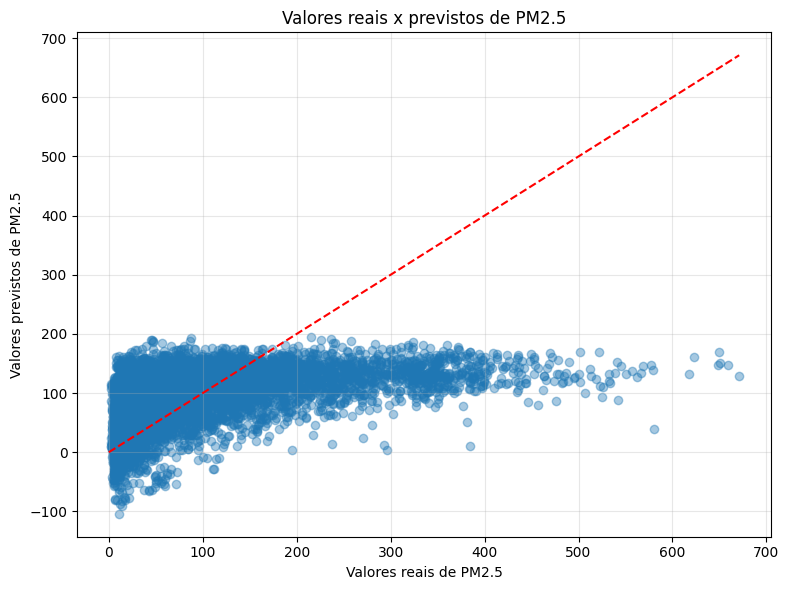

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_teste, previsoes, alpha=0.4)
plt.xlabel('Valores reais de PM2.5')
plt.ylabel('Valores previstos de PM2.5')
plt.title('Valores reais x previstos de PM2.5')

# Linha de referência
limite = max(y_teste.max(), previsoes.max())
plt.plot([0, limite], [0, limite], 'r--')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretação do gráfico

O gráfico mostra uma comparação entre os valores reais de PM2.5 e os valores previstos pelo modelo de regressão linear múltipla. É possível perceber que os pontos estão bastante espalhados em relação à linha de referência, mostrando que existem diferenças entre o que foi observado e o que o modelo calculou.

Também podemos observar que o modelo tem mais dificuldade para prever concentrações altas de PM2.5, muitas vezes apresentando valores menores do que os reais. Isso está de acordo com o resultado do R² de 0,2255, que indica que o modelo consegue explicar apenas uma parte das variações dos dados.

Dessa forma, o modelo consegue identificar algumas relações presentes nos dados, mas ainda apresenta limitações para realizar previsões mais precisas.

## 10. Regressão Logística Binária

A regressão logística binária é uma técnica estatística utilizada para dividir os dados em duas categorias diferentes.

Neste projeto, vamos utilizar esse modelo para classificar os registros de concentração de PM2.5 da seguinte forma:

- Classe 0: concentração abaixo de 100 µg/m³.
- Classe 1: concentração igual ou superior a 100 µg/m³.

Para fazer essa classificação, serão utilizadas informações meteorológicas, com o objetivo de calcular a probabilidade de cada registro apresentar uma concentração mais elevada de PM2.5.

O valor de 100 µg/m³ foi escolhido como limite para separar as duas categorias durante a análise. É importante destacar que esse valor foi definido apenas para este estudo e não representa uma classificação oficial da qualidade do ar.

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Criação das categorias
y_classificacao = (df_limpo['pm2.5'] >= 100).astype(int)

# Seleção das variáveis explicativas
X_classificacao = df_limpo[
    ['TEMP', 'DEWP', 'PRES', 'Iws', 'Is', 'Ir', 'cbwd']
]

# Separação dos dados, mantendo a ordem cronológica
X_treino_log, X_teste_log, y_treino_log, y_teste_log = train_test_split(
    X_classificacao,
    y_classificacao,
    test_size=0.2,
    shuffle=False
)

# Pré-processamento
preprocessador_log = ColumnTransformer([
    ('numericas', StandardScaler(),
     ['TEMP', 'DEWP', 'PRES', 'Iws', 'Is', 'Ir']),
    ('categorica', OneHotEncoder(handle_unknown='ignore'),
     ['cbwd'])
])

# Construção do modelo
modelo_log = Pipeline([
    ('preprocessamento', preprocessador_log),
    ('classificador', LogisticRegression(max_iter=1000))
])

# Treinamento
modelo_log.fit(X_treino_log, y_treino_log)

# Previsões
previsoes_log = modelo_log.predict(X_teste_log)

print("Modelo de regressão logística treinado com sucesso!")
print("Registros para treinamento:", len(X_treino_log))
print("Registros para teste:", len(X_teste_log))

Modelo de regressão logística treinado com sucesso!
Registros para treinamento: 33405
Registros para teste: 8352


In [26]:
acuracia = accuracy_score(y_teste_log, previsoes_log)

print(f"Acurácia: {acuracia:.4f} ({acuracia*100:.2f}%)")

Acurácia: 0.6923 (69.23%)


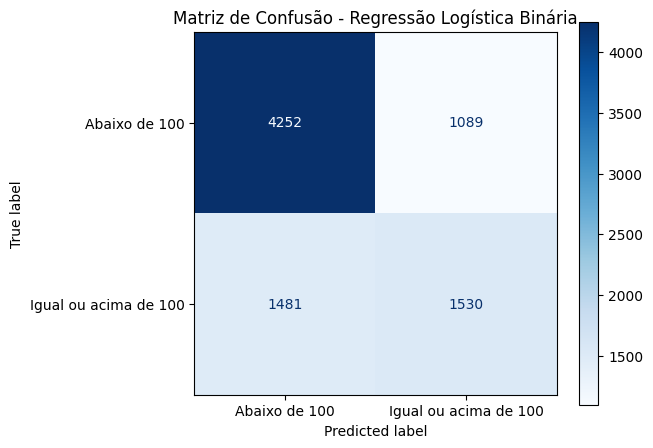

In [27]:
matriz = confusion_matrix(y_teste_log, previsoes_log)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Abaixo de 100', 'Igual ou acima de 100']
)

disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - Regressão Logística Binária')
plt.tight_layout()
plt.show()

### 10.1. Interpretação dos resultados

A acurácia do modelo foi de 69,23%, o que significa que ele conseguiu classificar corretamente aproximadamente 69 a cada 100 registros analisados.

De acordo com a matriz de confusão, que considera os 8.352 registros de teste, os resultados foram:

- 4.252 registros com concentração abaixo de 100 µg/m³ foram classificados corretamente;
- 1.530 registros com concentração igual ou superior a 100 µg/m³ também foram classificados corretamente;
- 1.089 registros com concentração abaixo de 100 µg/m³ foram classificados como elevados;
- 1.481 registros com concentração elevada foram classificados incorretamente como baixos.

Com esses resultados, podemos perceber que o modelo tem mais facilidade para identificar os registros com concentrações baixas do que aqueles com concentrações elevadas. Além disso, ele não conseguiu identificar 1.481 dos 3.011 registros que realmente apresentavam concentração elevada. Isso mostra que, apesar de apresentar resultados razoáveis, o modelo ainda precisa melhorar na identificação dos períodos com níveis mais altos de PM2.5.

### 10.2. Equação da regressão logística binária

O modelo calcula a probabilidade p de o PM2.5 ser igual ou superior a 100 µg/m³:

ln( p / (1 − p) ) = β0 + β1·X1 + β2·X2 + ...  &nbsp;&nbsp;→&nbsp;&nbsp; p = 1 / (1 + e^(−z))

O modelo foi treinado com variáveis padronizadas. Para a equação ficar legível, os coeficientes abaixo foram convertidos para as unidades originais das variáveis.

In [28]:
prep = modelo_log.named_steps['preprocessamento']
clf = modelo_log.named_steps['classificador']

nomes_num = ['TEMP', 'DEWP', 'PRES', 'Iws', 'Is', 'Ir']
escala = prep.named_transformers_['numericas']
nomes_cat = list(prep.named_transformers_['categorica'].get_feature_names_out(['cbwd']))

coefs = clf.coef_[0]
coef_num = coefs[:len(nomes_num)] / escala.scale_
coef_cat = coefs[len(nomes_num):]
intercepto = clf.intercept_[0] - np.sum(coefs[:len(nomes_num)] * escala.mean_ / escala.scale_)

print(f"z = {intercepto:.4f}")
for nome, valor in zip(nomes_num, coef_num):
    print(f"    {valor:+.4f} * {nome}")
for nome, valor in zip(nomes_cat, coef_cat):
    print(f"    {valor:+.4f} * {nome}  (1 se a direção do vento for essa, 0 caso contrário)")
print()
print("P(PM2.5 >= 100) = 1 / (1 + e^(-z))")

z = 40.6651
    -0.1677 * TEMP
    +0.1288 * DEWP
    -0.0386 * PRES
    -0.0128 * Iws
    -0.1035 * Is
    -0.2097 * Ir
    -0.5353 * cbwd_NE  (1 se a direção do vento for essa, 0 caso contrário)
    -0.6024 * cbwd_NW  (1 se a direção do vento for essa, 0 caso contrário)
    +0.3910 * cbwd_SE  (1 se a direção do vento for essa, 0 caso contrário)
    +0.0179 * cbwd_cv  (1 se a direção do vento for essa, 0 caso contrário)

P(PM2.5 >= 100) = 1 / (1 + e^(-z))


**Interpretação:** coeficientes positivos aumentam a chance de PM2.5 ≥ 100 µg/m³ e coeficientes negativos diminuem. Pela equação, um ponto de orvalho (DEWP) maior aumenta a chance de concentração elevada, enquanto temperatura (TEMP), pressão (PRES) e velocidade do vento (Iws) maiores diminuem essa chance. Isso combina com a regressão linear. As variáveis `cbwd_...` representam a direção do vento: vento de sudeste (SE) aumenta a chance, e ventos de nordeste (NE) e noroeste (NW) diminuem. (cv = calmaria).

### 10.3. Classificação de novos registros

Dois cenários hipotéticos serão classificados com o modelo, usando todas as variáveis explicativas (mais de duas).

In [29]:
novos_registros = pd.DataFrame({
    'TEMP': [-2, 12],
    'DEWP': [-5, -15],
    'PRES': [1025, 1012],
    'Iws': [1.5, 60],
    'Is': [0, 0],
    'Ir': [0, 0],
    'cbwd': ['cv', 'NW']
})

probs = modelo_log.predict_proba(novos_registros)[:, 1]
classes = modelo_log.predict(novos_registros)

nomes_cenarios = ['Cenário 1: frio, vento fraco, calmaria', 'Cenário 2: ameno, vento forte do noroeste']
for i in range(len(novos_registros)):
    rotulo = 'Igual ou acima de 100 µg/m³' if classes[i] == 1 else 'Abaixo de 100 µg/m³'
    print(nomes_cenarios[i])
    print(f"  Probabilidade de PM2.5 >= 100: {probs[i]*100:.2f}%")
    print(f"  Classe prevista: {rotulo}")
    print()

Cenário 1: frio, vento fraco, calmaria
  Probabilidade de PM2.5 >= 100: 69.13%
  Classe prevista: Igual ou acima de 100 µg/m³

Cenário 2: ameno, vento forte do noroeste
  Probabilidade de PM2.5 >= 100: 2.42%
  Classe prevista: Abaixo de 100 µg/m³



**Interpretação:** no Cenário 1 (frio, calmaria e vento fraco) o modelo estima 69,13% de chance de PM2.5 ≥ 100 µg/m³, então classifica o registro como concentração elevada. No Cenário 2 (vento forte do noroeste) a chance cai para 2,42%, e o registro é classificado como abaixo de 100 µg/m³. Isso concorda com a ideia de que vento forte dispersa os poluentes. Lembrando que o modelo acerta cerca de 69% dos casos, então a classificação é uma estimativa, não uma certeza.

# 11. Conclusões e limitações

**Principais resultados**

- Distribuição normal: a probabilidade de o PM2.5 ficar abaixo da média é de 50%, enquanto a probabilidade de ficar acima da mediana é de 61,38%. Porém, os dados apresentam uma distribuição assimétrica à direita, já que a mediana (72) é menor que a média (98,6). Por isso, a distribuição normal deve ser considerada apenas uma aproximação.

- Testes de hipóteses: nos dois testes realizados, com níveis de significância de 6% e 9%, não foi possível rejeitar a hipótese nula (H0).

- Regressão simples: o ponto de orvalho apresentou uma relação fraca com a concentração de PM2.5, explicando aproximadamente 2,9% da variação dos dados (R² = 0,0294).

- Regressão múltipla: utilizando temperatura (TEMP), ponto de orvalho (DEWP), pressão atmosférica (PRES) e velocidade do vento (Iws), o R² chegou a aproximadamente 0,224. Apesar de o modelo apresentar significância no teste F, ele ainda explica apenas uma parte da variação do PM2.5.

- Regressão logística: o modelo apresentou uma acurácia de 69,23% ao classificar os registros com concentração abaixo ou igual/superior a 100 µg/m³. Ele identificou melhor os registros de concentração baixa e deixou de detectar 1.481 dos 3.011 registros que apresentavam concentração elevada.

**Relação com o problema (CitizenTech)**

Os resultados mostram que as condições meteorológicas têm relação com a concentração de PM2.5 em Pequim. Fatores como vento, temperatura e umidade ajudam a entender algumas mudanças nos níveis de poluição. No entanto, essas informações não são suficientes para prever com precisão os períodos de maior concentração do poluente.

Dentro da proposta CitizenTech, essa análise mostra como os dados podem ser utilizados para acompanhar a qualidade do ar e contribuir para o desenvolvimento de soluções tecnológicas voltadas à população.

**Limitações**

- A base de dados contém informações de apenas uma cidade, Pequim, e corresponde ao período de 2010 a 2014.
- Como os registros foram coletados por hora, existe a possibilidade de que os valores tenham relação com os horários anteriores, o que pode afetar a hipótese de independência utilizada nos modelos.
- A concentração de PM2.5 não apresenta uma distribuição normal, e algumas variáveis, como temperatura (TEMP), ponto de orvalho (DEWP) e pressão atmosférica (PRES), possuem uma forte relação entre si.
- A base não possui informações diretas sobre as fontes de poluição, como trânsito, atividades industriais e aquecimento.
- Os resultados identificam relações entre as variáveis, mas não comprovam que uma delas seja a causa direta do aumento ou da redução da concentração de PM2.5.